In [3]:
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 
import seaborn as sns
%matplotlib inline

In [4]:
df = pd.read_csv("1-studyhours.csv")
df.head()

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


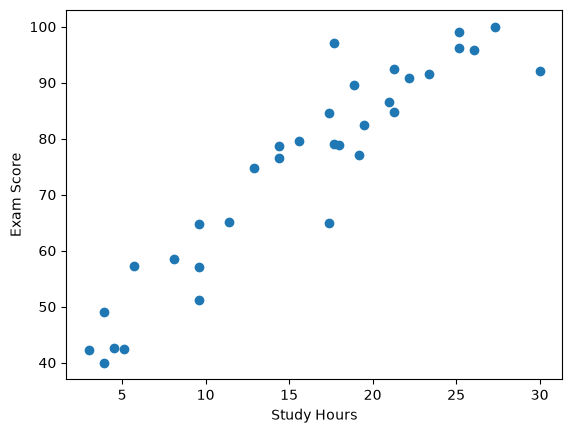

In [5]:
plt.scatter(df["Study Hours"], df["Exam Score"])
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.show()

In [9]:
# independent and dependent features 
X = df[["Study Hours"]] # independent features, x'i df olarak almaliyiz o yuzden cift []
y = df["Exam Score"] # dependent features

In [10]:
type(X)

pandas.DataFrame

In [11]:
type(y)

pandas.Series

In [16]:
# Test - train split
from sklearn.model_selection import train_test_split

In [17]:
from pandas import test
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2 , random_state = 15) 
# X'in %20si x test'e geri kalan x train'e ayni sekilde y'de de ayni 

In [ ]:
# Standardize the data set, X_standart = X - MEAN / standart sapma

In [18]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) # fit = standardize ediyor, transform ise islemin degiskene uygulanmasi
X_test = scaler.transform(X_test) # fit yapmamamizin sebebi train ile alakali bir sey bilmemesi lazim leak olmamasi icin
X_train

array([[ 0.11794385],
       [-0.97424848],
       [-1.68837424],
       [ 0.32798083],
       [ 0.36998823],
       [-0.7222041 ],
       [ 0.41199563],
       [-0.97424848],
       [ 0.11794385],
       [-0.30213013],
       [ 0.15995124],
       [ 0.66404001],
       [-0.13410054],
       [ 1.50418796],
       [-0.51216711],
       [ 0.15995124],
       [-0.30213013],
       [ 1.21013618],
       [ 1.33615837],
       [ 0.7900622 ],
       [-1.77238903],
       [-1.89841122],
       [ 0.20195864],
       [ 1.88225453],
       [-1.18428547],
       [ 1.21013618]])

In [21]:
from sklearn.linear_model import LinearRegression
regression = LinearRegression()

In [22]:
regression.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[16.18]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,76.91
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5.1]


In [23]:
print("Coefficient: ", regression.coef_)
print("Intercept: ", regression.intercept_)

Coefficient:  [16.17860223]
Intercept:  76.9076923076923


In [ ]:
# yani denklemimiz y = 76.91 + 16.18x cikti, ama su an bu sonuc standardize edilmis olarak cikacak

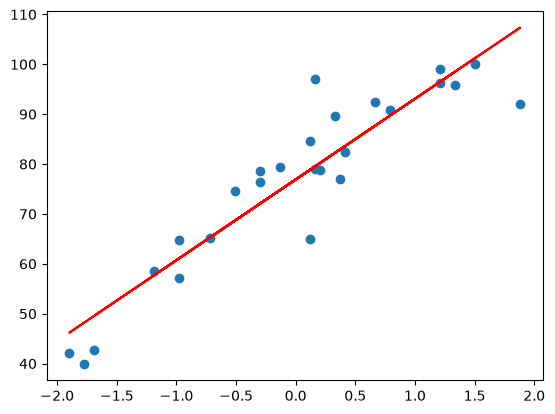

In [24]:
plt.scatter(X_train, y_train)
plt.plot(X_train, regression.predict(X_train), "r")
plt.show()

In [27]:
# x = 20 ise y = ? 
regression.predict([[20]])

array([400.47973694])

In [ ]:
regression.predict(scaler.transform([[20]])) # 20 saat calisan icin notunu 91 olarak tahmin etti 

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([91.30511371])

In [ ]:
regression.predict(scaler.transform([[10]])) # 10 saat calisan icin notunu 71 olarak tahmin etti 

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([71.14872375])

In [ ]:
# prediction with test data

In [35]:
y_pred_test = regression.predict(X_test)


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [36]:
mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
print("mse: ", mse)
print("mae: ", mae)
print("rmse: ", rmse)

mse:  146.0260151595823
mae:  10.821978021978014
rmse:  12.084122440607025


In [38]:
r2 = r2_score(y_test, y_pred_test)
print("r2 score: ", r2)

r2 score:  0.6017506301716422


In [39]:
# adjusted r2 
1 -  (1 - r2) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)

0.5221007562059706